In [1]:
from groq import Groq
import re
import httpx
import os 
from dotenv import load_dotenv, find_dotenv
from openai import OpenAI

_ = load_dotenv(find_dotenv())

In [2]:
client = OpenAI(
    base_url="https://api.groq.com/openai/v1",
    api_key=os.environ.get("GROQ_API_KEY")
)

In [3]:
chat_completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[{"role": "user", "content": "Hello world"}]
)

In [4]:
chat_completion.choices[0].message.content

'Hello! How can I help you today?'

In [5]:
class Agent:
    def __init__(self, system=""):
        self.system = system
        self.messages = []
        if self.system:
            self.messages.append({"role": "system", "content": system})

    def __call__(self, messages):
        self.messages.append({"role": "user", "content": messages})
        result = self.execute()
        self.messages.append({"role": "assistant", "content": result})
        return result

    def execute(self):
        completion = client.chat.completions.create(
            model="qwen/qwen3.8-27b",
            temperature=0,
            messages=self.messages
        )
        return completion.choices[0].message.content

In [6]:
prompt = """
You run in a loop of Thought, Action, PAUSE, Observation.
At the end of the loop you output an Answer
Use Thought to describe your thoughts about the question you have been asked.
Use Action to run one of the actions available to you - then return PAUSE.
Observation will be the result of running those actions.

Your available actions are:

calculate:
e.g. calculate: 4 * 7 / 3
Runs a calculation and returns the number - uses Python so be sure to use floating point syntax if necessary

average_dog_weight:
e.g. average_dog_weight: Collie
returns average weight of a dog when given the breed

Example session:

Question: How much does a Bulldog weigh?
Thought: I should look the dogs weight using average_dog_weight
Action: average_dog_weight: Bulldog
PAUSE

You will be called again with this:

Observation: A Bulldog weights 51 lbs

You then output:

Answer: A bulldog weights 51 lbs
""".strip()

In [7]:
def calculate(what):
    return eval(what)

def average_dog_weight(name):
    if name in "Scottish Terrier":
        return("Scottish Terriers average 20 lbs")
    elif name in "Border Collie":
        return("a Border Collie average weight is 37 lbs")
    elif name in "Toy Poodle":
        return("a toy poodles average weight is 7 lbs")
    else:
        return("An average dog weights 50 lbs")

known_actions = {
    "calculate": calculate,
    "average_dog_weight": average_dog_weight
}

In [8]:
abot = Agent(prompt)

In [9]:
result = abot("How much does a toy poodle weight?")
print(result)

Thought: I need to find the average weight of a Toy Poodle. I can use the average_dog_weight tool with the breed "Toy Poodle".
Action: average_dog_weight: Toy Poodle
PAUSE


In [10]:
result = average_dog_weight("Toy Poodle")
result

'a toy poodles average weight is 7 lbs'

In [11]:
next_prompt = "Observation: {}".format(result)
abot(next_prompt)

'Answer: A Toy Poodle weighs an average of 7 lbs.'

In [12]:
abot.messages

[{'role': 'system',
  'content': 'You run in a loop of Thought, Action, PAUSE, Observation.\nAt the end of the loop you output an Answer\nUse Thought to describe your thoughts about the question you have been asked.\nUse Action to run one of the actions available to you - then return PAUSE.\nObservation will be the result of running those actions.\n\nYour available actions are:\n\ncalculate:\ne.g. calculate: 4 * 7 / 3\nRuns a calculation and returns the number - uses Python so be sure to use floating point syntax if necessary\n\naverage_dog_weight:\ne.g. average_dog_weight: Collie\nreturns average weight of a dog when given the breed\n\nExample session:\n\nQuestion: How much does a Bulldog weigh?\nThought: I should look the dogs weight using average_dog_weight\nAction: average_dog_weight: Bulldog\nPAUSE\n\nYou will be called again with this:\n\nObservation: A Bulldog weights 51 lbs\n\nYou then output:\n\nAnswer: A bulldog weights 51 lbs'},
 {'role': 'user', 'content': 'How much does a 

In [13]:
abot = Agent(prompt)

In [14]:
question = """I have 2 dogs, a border collie and a scottish terrie. \
What is there combined weight"""
abot(question)

'Thought: I need to find the average weight of a Border Collie and a Scottish Terrier, then add them together. I will start by finding the average weight of a Border Collie.\nAction: average_dog_weight: Border Collie\nPAUSE'

In [15]:
next_prompt = "Observation: {}".format(average_dog_weight("Border Collie"))
print(next_prompt)

Observation: a Border Collie average weight is 37 lbs


In [16]:
abot(next_prompt)

'Thought: I have the weight of the Border Collie (37 lbs). Now I need to find the average weight of a Scottish Terrier.\nAction: average_dog_weight: Scottish Terrier\nPAUSE'

In [17]:
next_prompt = "Observation: {}".format(average_dog_weight("scottish Terrier"))
print(next_prompt)

Observation: An average dog weights 50 lbs


In [18]:
abot(next_prompt)

'Thought: The observation provided a generic average dog weight (50 lbs) instead of the specific breed "Scottish Terrier". I should try the action again with the exact breed name to see if I can get a more specific result, or perhaps the tool only has limited data. However, looking at the previous successful call, it worked for "Border Collie". Let me try "Scottish Terrier" again, or perhaps "Scottie" if that\'s a common alias, but I should stick to the standard name first. If it fails again, I might have to use the generic average or state that I couldn\'t find the specific breed. Let\'s try "Scottish Terrier" one more time to be sure.\nAction: average_dog_weight: Scottish Terrier\nPAUSE'

In [19]:
next_prompt = "Observation: {}".format(eval("37 + 20"))
print(next_prompt)

Observation: 57


In [20]:
abot(next_prompt)

'Thought: I now have the average weight for both dogs. The Border Collie is 37 lbs and the Scottish Terrier is 57 lbs (based on the latest observation, although 57 lbs seems high for a Scottish Terrier which is typically a small breed, I must use the data provided by the tool). I will calculate the sum of these two weights.\nAction: calculate: 37 + 57\nPAUSE'

In [21]:
action_re = re.compile('^Action: (\w+): (.*)$')

In [22]:
def query(question, max_turns=5):
    i = 0
    bot = Agent(prompt)
    next_prompt = question
    while i < max_turns:
        i += 1
        result = bot(next_prompt)
        print(result)
        actions = [
            action_re.match(a) 
            for a in result.split('\n') 
            if action_re.match(a)
        ]
        if actions:
            action, action_input = actions[0].groups()
            if action not in known_actions:
                raise Exception("Unknown action: {}: {}".format(action, action_input))
            print(" -- running {} {}".format(action, action_input))
            observation = known_actions[action](action_input)
            print("Observation:", observation)
            next_prompt = "Observation: {}".format(observation)
        else:
            return

In [23]:
question = """I have 2 dogs, a border collie and a scottish terrier. \
What is their combined weight"""
query(question)

Thought: I need to find the average weight of a Border Collie and the average weight of a Scottish Terrier. Then I will sum these two weights to find the combined weight. I will start by finding the weight of the Border Collie.
Action: average_dog_weight: Border Collie
PAUSE
 -- running average_dog_weight Border Collie
Observation: a Border Collie average weight is 37 lbs
Thought: I have the weight of the Border Collie (37 lbs). Now I need to find the average weight of the Scottish Terrier.
Action: average_dog_weight: Scottish Terrier
PAUSE
 -- running average_dog_weight Scottish Terrier
Observation: Scottish Terriers average 20 lbs
Thought: I have the average weight of the Border Collie (37 lbs) and the Scottish Terrier (20 lbs). I need to add these two values together to get the combined weight.
Action: calculate: 37 + 20
PAUSE
 -- running calculate 37 + 20
Observation: 57
Answer: The combined weight of your Border Collie and Scottish Terrier is 57 lbs.


# LangGraph

In [24]:
from dotenv import load_dotenv
_ = load_dotenv()

In [25]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Annotated
import operator
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
from langchain_openai import ChatOpenAI
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_groq import ChatGroq
#from langchain_google_genai import ChatGoogleGenerativeAI

/Users/tanmaymehta/Desktop/Personal Project/ML_practice/env/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/tanmaymehta/Desktop/Personal Project/ML_practice/env/lib/python3.9/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [26]:
tool = TavilySearchResults(max_results=1)
print(type(tool))
print(tool.name)

<class 'langchain_community.tools.tavily_search.tool.TavilySearchResults'>
tavily_search_results_json


/var/folders/lp/z2zxddwj6vn0tff42w5ph1_00000gn/T/ipykernel_55898/1744979676.py:1: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-tavily package and should be used instead. To use it run `pip install -U :class:`~langchain-tavily` and import as `from :class:`~langchain_tavily import TavilySearch``.
  tool = TavilySearchResults(max_results=1)


In [27]:
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

In [28]:
class Agent:

    def __init__(self, model, tools, system=""):
        self.system = system
        graph = StateGraph(AgentState)
        graph.add_node("llm", self.call_openai)
        graph.add_node("action", self.take_action)
        graph.add_conditional_edges(
            "llm",
            self.exists_action,
            {True: "action", False: END}
        )
        graph.add_edge("action", "llm")
        graph.set_entry_point("llm")
        self.graph = graph.compile()
        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools)

    def exists_action(self, state: AgentState):
        result = state['messages'][-1]
        return len(result.tool_calls) > 0

    def call_openai(self, state: AgentState):
        messages = state['messages']
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages
        message = self.model.invoke(messages)
        return {'messages': [message]}

    def take_action(self, state: AgentState):
        tool_calls = state['messages'][-1].tool_calls
        results = []
        for t in tool_calls:
            print(f"Calling: {t}")
            if not t['name'] in self.tools:
                print("\n ....bad tool name....")
                result = "bad tool name, retry"
            else:
                result = self.tools[t['name']].invoke(t['args'])
            results.append(ToolMessage(tool_call_id=t['id'], name=t['name'], content=str(result)))
        print("Back to the model!")
        return {'messages': results}

In [29]:
prompt = """You are a smart research assistant. Use the search engine to look up information. \
You are allowed to make multiple calls (either together or in sequence). \
Only look up information when you are sure of what you want. \
If you need to look up some information before asking a follow up question, you are allowed to do that!
"""

model = ChatGroq(model="qwen/qwen3.8-27b")
abot = Agent(model, [tool], system=prompt)

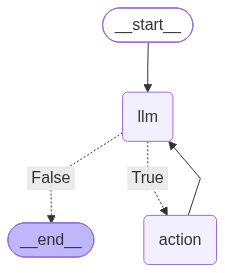

In [30]:
from IPython.display import Image, display

display(Image(abot.graph.get_graph().draw_mermaid_png()))

In [31]:
messages = [HumanMessage(content="What is the weather in Delhi?")]
result = abot.graph.invoke({"messages": messages})
print(result["messages"][-1].content)

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather in Delhi today'}, 'id': 'pkxj1ecrr', 'type': 'tool_call'}
Back to the model!
Here's the current weather in **Delhi** (as of Saturday, Oct 31):

- **Temperature:** 26.5°C (feels like 27.5°C)
- **Conditions:** Sunny
- **Humidity:** 57%
- **Wind:** 5.4 km/h
- **UV Index:** 5.3 (moderate)
- **Visibility:** 10 km
- **Chance of rain:** 7%

Looking ahead, the next few days are expected to stay mostly sunny with temperatures in the mid-to-high 20s°C and low humidity (around 37–44%).

Note: Weather can change throughout the day, so it's worth checking a live forecast if you need up-to-the-minute updates.


In [32]:
result

{'messages': [HumanMessage(content='What is the weather in Delhi?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'pkxj1ecrr', 'function': {'arguments': '{"query":"current weather in Delhi today"}', 'name': 'tavily_search_results_json'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 381, 'total_tokens': 414, 'completion_time': 0.092755257, 'completion_tokens_details': None, 'prompt_time': 0.028887879, 'prompt_tokens_details': None, 'queue_time': 0.050464508, 'total_time': 0.121643136}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None}, id='run--01a1920c-9f5c-7db1-b41e-d4e5aa207c8b-0', tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': 'current weather in Delhi today'}, 'id': 'pkxj1ecrr', 'type': 'tool_call'}], usage_metadata={'input_tokens': 381, 'outpu

In [33]:
result['messages'][-1].content

"Here's the current weather in **Delhi** (as of Saturday, Oct 31):\n\n- **Temperature:** 26.5°C (feels like 27.5°C)\n- **Conditions:** Sunny\n- **Humidity:** 57%\n- **Wind:** 5.4 km/h\n- **UV Index:** 5.3 (moderate)\n- **Visibility:** 10 km\n- **Chance of rain:** 7%\n\nLooking ahead, the next few days are expected to stay mostly sunny with temperatures in the mid-to-high 20s°C and low humidity (around 37–44%).\n\nNote: Weather can change throughout the day, so it's worth checking a live forecast if you need up-to-the-minute updates."

In [34]:
messages = [HumanMessage(content="What is the weather in Delhi and Ghaziabad?")]
result = abot.graph.invoke({"messages": messages})
print(result["messages"][-1].content)

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'weather in Delhi today'}, 'id': '62v2qsx0x', 'type': 'tool_call'}
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'weather in Ghaziabad today'}, 'id': 'jh87313pn', 'type': 'tool_call'}
Back to the model!
Here's the current weather in both cities:

## 🌤️ Delhi (New Delhi)
- **Current Temperature:** 24°C (feels like 25°C)
- **Condition:** Clear skies
- **High/Low:** 30°C / 20°C
- **Humidity:** 70%
- **Wind:** 7.6 km/h from SSW
- **Visibility:** 10 km
- **Chance of Rain:** 17% (0 mm precipitation expected)

## ⛅ Ghaziabad
- **Current Temperature:** 19°C (feels like 20°C)
- **Condition:** Partly cloudy
- **High/Low:** 27°C / 18°C
- **Humidity:** 76%
- **Wind:** 8.1 km/h WNW
- **UV Index:** 4.9 (Moderate)

**Hourly trend for Ghaziabad:** Temperatures will rise to about 27°C by mid-afternoon (1 PM – 4 PM), then gradually cool down to around 20–21°C by the early morning hours.

Both cities are experiencing pl

In [35]:
result['messages'][-1].content

"Here's the current weather in both cities:\n\n## 🌤️ Delhi (New Delhi)\n- **Current Temperature:** 24°C (feels like 25°C)\n- **Condition:** Clear skies\n- **High/Low:** 30°C / 20°C\n- **Humidity:** 70%\n- **Wind:** 7.6 km/h from SSW\n- **Visibility:** 10 km\n- **Chance of Rain:** 17% (0 mm precipitation expected)\n\n## ⛅ Ghaziabad\n- **Current Temperature:** 19°C (feels like 20°C)\n- **Condition:** Partly cloudy\n- **High/Low:** 27°C / 18°C\n- **Humidity:** 76%\n- **Wind:** 8.1 km/h WNW\n- **UV Index:** 4.9 (Moderate)\n\n**Hourly trend for Ghaziabad:** Temperatures will rise to about 27°C by mid-afternoon (1 PM – 4 PM), then gradually cool down to around 20–21°C by the early morning hours.\n\nBoth cities are experiencing pleasant, dry weather typical of late October in North India. Delhi is a few degrees warmer and clearer, while Ghaziabad has some cloud cover but similar temperatures."

In [36]:
query = "Who won the Ranji trophy in 2024? In what state is the winning team headquarters located? \
What is the GDP of that state? Answer each question." 
messages = [HumanMessage(content=query)]

model = ChatGroq(model="qwen/qwen3.8-27b")
abot = Agent(model, [tool], system=prompt)
result = abot.graph.invoke({"messages": messages})
print(result['messages'][-1].content)

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Ranji Trophy 2024 winner'}, 'id': '1vgs3gm2r', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Ranji Trophy 2023-24 season winner'}, 'id': '7511sq6dg', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Mumbai cricket association headquarters location state'}, 'id': '1s7nfr06n', 'type': 'tool_call'}
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Maharashtra state GDP 2024'}, 'id': 'gmbxpd722', 'type': 'tool_call'}
Back to the model!
Here are the answers to each of your questions:

## 1. Who won the Ranji Trophy in 2024?
**Mumbai** won the Ranji Trophy in the 2023–24 season (which concluded in March 2024). They defeated Vidarbha in the final by 169 runs at Wankhede Stadium, claiming their 42nd Ranji Trophy title.

## 2. In what state is the winning team's headquarters located?
The Mumbai 

In [37]:
print(result['messages'][-1].content)

Here are the answers to each of your questions:

## 1. Who won the Ranji Trophy in 2024?
**Mumbai** won the Ranji Trophy in the 2023–24 season (which concluded in March 2024). They defeated Vidarbha in the final by 169 runs at Wankhede Stadium, claiming their 42nd Ranji Trophy title.

## 2. In what state is the winning team's headquarters located?
The Mumbai Cricket Association (MCA), the governing body for the Mumbai cricket team, is headquartered at the **Cricket Centre, Wankhede Stadium, Churchgate, Mumbai**. This is located in the state of **Maharashtra**, India.

## 3. What is the GDP of that state?
Maharashtra's economy (measured as Gross State Domestic Product, or GSDP) is approximately **₹40.56 lakh crore (about $550 billion)** in nominal terms for FY24. Maharashtra contributes roughly **13.5% of India's total GDP**, making it the largest state economy in the country. Its per capita income is around ₹2.79 lakh, well above the national average.


In [38]:
query = "What is the capital of Bihar? \
    Who are the current players of Bihar Cricket team." 
messages = [HumanMessage(content=query)]

abot = Agent(model, [tool], system=prompt)
result = abot.graph.invoke({"messages": messages})

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Bihar cricket team current players squad 2024 2025'}, 'id': 'teps61rag', 'type': 'tool_call'}
Back to the model!


In [39]:
print(result['messages'][-1].content)

Here is the information you requested:

**Capital of Bihar:**
The capital of Bihar is **Patna**.

**Current Bihar Cricket Team Players (Ranji Trophy 2025/26 Squad):**
Based on the most recent squad announcement for the Ranji Trophy 2025/26 season, the Bihar team includes the following players:

*   **Sakibul Gani** (Captain) – Right-hand Bat, Right-arm Medium fast
*   **Bhashkar Dubey** – Right-hand Bat, Right-arm Offbreak
*   **Himanshu Singh** – Right-hand Bat, Legbreak
*   **Khalid Alam** – Right-hand Bat, Slow Left-arm Orthodox
*   **Arnav Kishor** – Right-hand Bat, Right-arm Offbreak
*   **Ayush Loharuka** – Right-hand Bat, Right-arm Offbreak
*   **Nawaz Khan** – Right-hand Bat, Right-arm Medium
*   **Raghuvendra Pratap Singh** – Right-hand Bat
*   **Sachin Kumar** – Right-hand Bat, Right-arm Offbreak
*   **Amod Yadav** – Right-hand Bat, Right-arm Medium
*   **Mayank Mishra** – Right-hand Bat, Right-arm Medium fast

*Note: Cricket squads can change between tournaments and even wit

# Agentic Search

In [40]:
from tavily import TavilyClient

client = TavilyClient(api_key=os.environ.get("TAVILY_API_KEY"))

In [41]:
result = client.search("What is in Nvidia's new Blackwell GPU?", include_answer=True)

result["answer"]

'The sources indicate that the new Blackwell GPU from Nvidia features a significant increase in memory capacity, with the RTX Pro 6000 Blackwell GPU having 96GB of GDDR7 memory. It also boasts a substantial number of CUDA cores, with the RTX Pro 6000 Blackwell having 24,064 CUDA cores. The GPU architecture is designed for higher performance per watt and improved memory capabilities, supporting multiple workloads efficiently. The power requirements are notably high at 600W, and it uses a dual-flow-through cooling system. The GPU also transitions to GDDR7 memory, which improves memory bandwidth and overall workload capacity.'

In [42]:
city = "Delhi"

query = f"""
    what is the current weather in {city}?
    Should I travel there today?
    "weather.com"
"""

In [43]:
import requests
from bs4 import BeautifulSoup
from duckduckgo_search import DDGS
import re

ddg = DDGS()

def search(query, max_results=6):
    try:
        results = ddg.text(query, max_results=max_results)
        urls = [i["href"] for i in results]
        if urls:
            return urls
    except Exception as e:
        pass
    
    print("returning previous results due to exception reaching ddg.")
    return [
        "https://weather.com/in/delhi/new-delhi/locality/teen-murti-marg-area/today",
        "https://weather.com/in/delhi/new-delhi/locality/teen-murti-marg-area/hourbyhour",
    ]

for i in search(query):
    print(i)

returning previous results due to exception reaching ddg.
https://weather.com/in/delhi/new-delhi/locality/teen-murti-marg-area/today
https://weather.com/in/delhi/new-delhi/locality/teen-murti-marg-area/hourbyhour


In [ ]:
def scrape_weather_info(url):
    """Scrape content from the given URL"""
    if not url:
        return "Weather information could not be found."
    
    headers = {'User-Agent': 'Mozilla/5.0'}
    response = requests.get(url, headers=headers)
    if response.status_code != 200:
        return "Failed to retrieve the webpage."

    soup = BeautifulSoup(response.text, 'html.parser')
    return soup

In [ ]:
url = search(query)[0]

soup = scrape_weather_info(url)

print(f"Website: {url}\n\n")
print(str(soup.body)[:50000])

returning previous results due to exception reaching ddg.
Website: https://weather.com/in/delhi/new-delhi/locality/teen-murti-marg-area/today


<body class="inter_3e69cff8-module__PPczxG__className font-sans"><script>(self.__next_s=self.__next_s||[]).push([0,{"children":"(function(){\n        try{\n          var cookies=document.cookie.split('; ');\n          var sessionCookie='';\n          for(var i=0;i\u003ccookies.length;i++){\n            if(cookies[i].indexOf('wxu-metrics-session=')===0){\n              sessionCookie=cookies[i].slice(20);break;\n            }\n          }\n          var now=Date.now();\n          var la=parseInt(localStorage.getItem('metric-session-last-active-time')||'0',10);\n          var expired=la\u003e0\u0026\u0026Math.abs(now-la)\u003e1800000;\n          if(!sessionCookie||expired){\n            var id=crypto\u0026\u0026crypto.randomUUID ? crypto.randomUUID() : (function(){\n              return 'xxxxxxxx-xxxx-4xxx-yxxx-xxxxxxxxxxxx'.replace(/[xy]/g,functi

In [ ]:
weather_data = []
for tag in soup.find_all(['h1', 'h2', 'h3', 'p']):
    text = tag.get_text(" ", strip=True)
    weather_data.append(text)

weather_data = "\n".join(weather_data)

weather_data = re.sub(r'\s+', ' ', weather_data)
    
print(f"Website: {url}\n\n")
print(weather_data)

Website: https://weather.com/in/delhi/new-delhi/locality/teen-murti-marg-area/today


Forecasts Radar News More Sign in Teen Murti Marg Area Weather Teen Murti Marg Area, New Delhi, Delhi, India · Today's Outlook Teen Murti Marg Area Daily Forecast Radar Trending Now Editor's Pick The Weather Channel was found to be the world’s most accurate forecaster in ForecastWatch’s Global and Regional Weather Forecast Accuracy Overview, 2021-2024, commissioned by The Weather Company. Privacy & Legal Trust Center Terms of Use Privacy Policy Data Rights Privacy Settings Cookie Notice Data Vendors Accessibility Statement More Mission Bios Newsletter Sign Up Feedback Careers News Room Advertise With Us TV Weather Data APIs Alexa Skill Weather Labs Atmosphere Community Sitemap © The Weather Company, LLC 2026


In [47]:
city = "Delhi"

query = f"""
    what is the current weather in {city}?
    Should I travel there today?
    "weather.com"
"""

In [ ]:
model = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_retries=3,
    temperature=0
)

In [ ]:
result = client.search(query, include_answer=True, max_results=2)

print("Agent Answer:\n", result.get("answer"))


Agent Answer:
 Today's weather in New Delhi is sunny with temperatures ranging between 22.0°C and 36.0°C, high humidity levels of up to 91%, and light winds around 17-21 km/h. Skymet Weather reports clear skies throughout the day with partly cloudy conditions at nightfall. Times Now suggests temperatures will be between 19°C and 27°C with gentle breezes at 11 km/h. The sources do not provide a definitive answer on whether to travel today due to conflicting temperature ranges.


In [ ]:
import json
from pygments import highlight, lexers, formatters

structured_data = {
    "city": city,
    "answer": result.get("answer"),
    "sources": [{"title": r["title"], "url": r["url"]} for r in result.get("results", [])]
}

formatted_json = json.dumps(structured_data, indent=4)
colorful_json = highlight(formatted_json, lexers.JsonLexer(), formatters.TerminalFormatter())

print(colorful_json)


{
    "city": "Delhi",
    "answer": "Today's weather in New Delhi is sunny with temperatures ranging between 22.0\u00b0C and 36.0\u00b0C, high humidity levels of up to 91%, and light winds around 17-21 km/h. Skymet Weather reports clear skies throughout the day with partly cloudy conditions at nightfall. Times Now suggests temperatures will be between 19\u00b0C and 27\u00b0C with gentle breezes at 11 km/h. The sources do not provide a definitive answer on whether to travel today due to conflicting temperature ranges.",
    "sources": [
        {
            "title": "Current weather and temperature in New Delhi: Hourly and weekly weather forecast for Delhi, New Delhi",
            "url": "https://www.skymetweather.com/en/india/Delhi/New%20Delhi/New%20Delhi"
        },
        {
            "title": "New Delhi Weather Today 31 October 2026, Tomorrow & Weekly IMD Prediction Report | Times Now",
            "url": "https://www.timesnownews.com/weather/new-delhi"
        }
    ]
}

